# Reporte de avance — clasificación de defectos en palta Hass

ResNet50 | Clases PICADURA y RUSSET | 25 de octubre de 2026

Este notebook resume el trabajo realizado hasta completar el experimento D1. Es un documento de consulta independiente del notebook de entrenamiento; no modifica imágenes, no carga modelos y no ejecuta experimentos.

**Estado del proyecto:** entorno GPU operativo, dataset auditado, B0 y V1 previamente evaluados, D1 entrenado y evaluado sobre validation. D2, fine-tuning y evaluación final de test pendientes.


## 1. Objetivo y alcance

Se busca distinguir dos defectos superficiales de palta Hass mediante clasificación con ResNet50: **PICADURA** y **RUSSET**. La dificultad principal es el desbalance de datos, especialmente la baja cantidad de muestras RUSSET.

Cada TIFF corresponde a una palta y contiene tres franjas horizontales de las cámaras de adquisición, con múltiples vistas por rotación. Se procesa el archivo completo como una sola muestra: no se separan las franjas ni sus vistas entre train, validation y test.

En esta etapa se evaluó si generar una copia fotométrica adicional por cada palta RUSSET de train (D1) mejora el rendimiento frente al modelo de referencia (B0).


## 2. Preparación del entorno

| Componente | Configuración / comprobación |
|---|---|
| Editor | Visual Studio Code conectado a Ubuntu mediante WSL2 |
| Python | 3.12.14 en `/home/tci_auto/.venvs/palta_gpu/bin/python` |
| Framework | TensorFlow 2.21.0 con soporte CUDA |
| GPU | NVIDIA GeForce RTX 3070 Ti Laptop GPU, detectada como `GPU:0` |
| Kernel | `palta_gpu (CUDA)` |
| Librerías comprobadas | NumPy, pandas, matplotlib, scikit-learn, Pillow, tifffile, scikit-image, SciPy, psutil |

Durante la configuración se corrigió el acceso de Jupyter a las bibliotecas CUDA mediante la configuración del kernel. Se verificó que TensorFlow reconociera la GPU y utilizara cuDNN.

El dataset permanece fuera de la carpeta del repositorio y no fue cargado a GitHub.


## 3. Dataset y auditoría de integridad

Distribución física original de las imágenes TIFF:

| Partición | PICADURA | RUSSET | Total |
|---|---:|---:|---:|
| train | 497 | 77 | 574 |
| validation | 107 | 21 | 128 |
| test | 106 | 21 | 127 |
| **Total** | **710** | **119** | **829** |

La auditoría verificó los hashes SHA-256 de los **829/829 archivos** contra el inventario del EDA. Se excluyeron lógicamente cuatro rutas involucradas en dos pares de duplicados exactos entre particiones; uno de los pares tenía etiquetas contradictorias.

| Partición | Originales | Exclusiones | Elegibles |
|---|---:|---:|---:|
| train | 574 | 2 | 572 |
| validation | 128 | 1 | 127 |
| test (reservado) | 127 | 1 | 126 |
| **Total** | **829** | **4** | **825** |

No se borraron ni modificaron los TIFF. La exclusión se aplica en las listas utilizadas por los experimentos. El conjunto test no se utiliza para seleccionar la mejor variante.


## 4. Condiciones experimentales

| Condición | Entrada (alto × ancho) | Cambio realizado | Estado |
|---|---|---|---|
| B0 | 256 × 512 | Referencia, sin augmentation | Evaluado anteriormente |
| V1 | 384 × 768 | Mayor resolución | Evaluado anteriormente |
| D1 | 256 × 512 | 1 copia fotométrica por RUSSET de train | **Evaluado ahora** |
| D2 | 256 × 512 | 2 copias fotométricas por RUSSET de train | Pendiente |
| V2 | 256 × 512 | Volteo horizontal | No ejecutado; altera el orden de captura |

**Protocolo común:** ResNet50 preentrenada en ImageNet con extractor congelado; cabeza de clasificación con Dropout y Dense softmax; Adam; lote 8; semilla 42; máximo 35 épocas; parada anticipada según `val_loss`. Los pesos de clase se recalculan para la distribución efectiva de cada condición.

**D1:** 572 imágenes originales elegibles en train + 77 copias fotométricas de RUSSET = **649 entradas efectivas** para entrenar la cabeza de clasificación. Las variaciones son leves ajustes de brillo y contraste realizados en memoria; no son 77 frutos nuevos. Validation permanece sin augmentation.


## 5. Ejecución de D1

Se completó la ejecución `D1_s42_03`. Se verificó nuevamente la integridad de los 829 archivos, se descargaron los pesos ImageNet para el nuevo entorno WSL y se extrajeron características de 572 imágenes de train, 127 de validation y 77 copias aumentadas de RUSSET.

Los primeros intentos `D1_s42_01` y `D1_s42_02` quedaron incompletos debido a una comprobación de equivalencia numérica demasiado estricta al comparar predicciones de la cabeza y del modelo completo. Se modificó la tolerancia de `rtol=1e-4, atol=1e-5` a `rtol=1e-3, atol=1e-4`, conservando la comprobación. Con esa modificación, D1 terminó y generó métricas y gráficas.

El máximo configurado fue de 35 épocas; las curvas guardadas muestran aproximadamente 19 épocas, compatible con la parada anticipada. No se realizó fine-tuning de las capas convolucionales.

**Carpeta de resultados:** `7. resultados/entrenamiento/D1_s42_03/`.


## 6. Resultados de validation

La evaluación corresponde a las mismas **127 imágenes elegibles de validation** para las condiciones comparadas.

| Métrica | B0 | V1 | D1 |
|---|---:|---:|---:|
| Accuracy | 0.8425 | 0.8583 | 0.8425 |
| Macro-F1 | 0.6604 | 0.6598 | **0.7033** |
| Balanced accuracy | 0.6384 | 0.6287 | **0.6956** |
| Recall de RUSSET | 0.3333 | 0.2857 | **0.4762** |
| RUSSET correctas | 7 de 21 | 6 de 21 | **10 de 21** |

Frente a B0, D1 incrementó el macro-F1 en **0.0429** (4.29 puntos porcentuales) y el recall de RUSSET en **14.29 puntos porcentuales**, equivalentes a tres aciertos adicionales. La exactitud global no cambió.

Esta mejora va acompañada de una reducción del recall de PICADURA: de 0.9434 en B0 a 0.9151 en D1. Por ello, es importante evaluar las dos clases, no solo el accuracy.


## 7. Matriz de confusión de D1

Las filas corresponden a la clase real y las columnas a la predicción.

| Real / Predicción | PICADURA | RUSSET |
|---|---:|---:|
| PICADURA | **97** | 9 |
| RUSSET | 11 | **10** |

Se clasificaron correctamente **107 de 127** imágenes. En particular, se reconocieron 10 de las 21 RUSSET; las otras 11 se confundieron con PICADURA.


![Matriz de confusión y reporte de clasificación D1](attachment:evidencia_image(20261025-203219).png)

*Matriz de confusión y reporte de clasificación D1. Fuente: salida real del experimento D1 compartida por el investigador.*

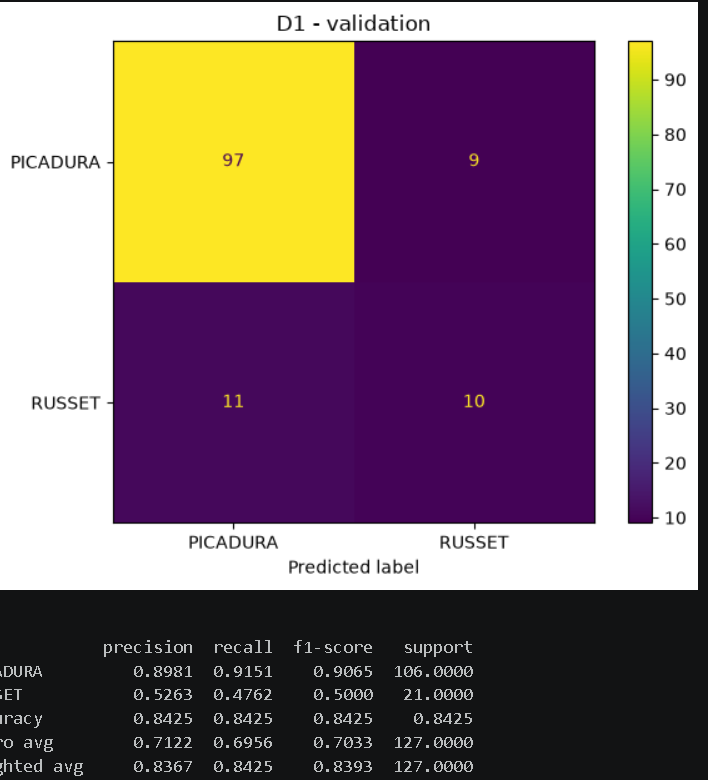

## 8. Curvas de aprendizaje

La pérdida de entrenamiento disminuye a lo largo de las épocas. La pérdida de validación presenta oscilaciones y se estabiliza en las etapas finales. La exactitud de entrenamiento termina por encima de la de validación; esto aconseja vigilar la generalización, aunque la diferencia de las curvas por sí sola no permite concluir sobreajuste.

Estas figuras corresponden a la ejecución real de D1; no se generaron resultados nuevos para este reporte.


![Historial de pérdida: train y validation](attachment:evidencia_image(20261025-203232).png)

*Historial de pérdida: train y validation. Fuente: salida real del experimento D1 compartida por el investigador.*

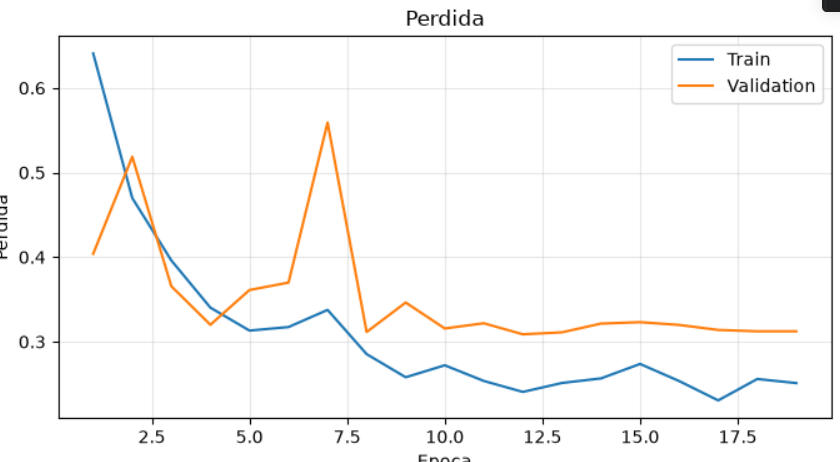

![Historial de accuracy: train y validation](attachment:evidencia_image(20261025-203243).png)

*Historial de accuracy: train y validation. Fuente: salida real del experimento D1 compartida por el investigador.*

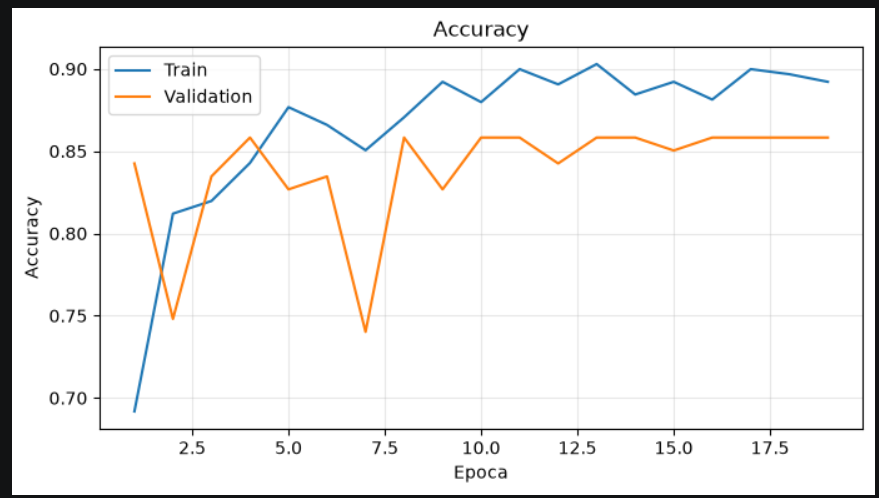

## 9. Conclusiones hasta esta etapa

1. El entorno Ubuntu WSL2 con TensorFlow y GPU NVIDIA quedó configurado y probado.
2. La auditoría preservó 825 imágenes elegibles sin modificar los 829 TIFF originales.
3. D1 completó la extracción, el entrenamiento y la evaluación en validation.
4. Entre B0, V1 y D1, **D1 muestra el mejor macro-F1 observado (0.7033)** y el mayor recall de RUSSET (0.4762).
5. La ganancia en RUSSET tiene un costo: se identifican menos PICADURA correctamente que con B0, aunque la exactitud global es la misma.

**Limitaciones:** validation contiene solo 21 imágenes RUSSET; se ha usado una única semilla; no se ha comprobado completamente la independencia de fruto/lote/sesión mediante trazabilidad; y test continúa reservado. La diferencia observada es exploratoria, no una mejora estadísticamente confirmada.


## 10. Próximas actividades

1. Ejecutar D2 (154 copias fotométricas de RUSSET) con el mismo protocolo, guardando los resultados en una carpeta nueva.
2. Comparar B0, V1, D1 y D2 mediante macro-F1, recall por clase, balanced accuracy y matrices de confusión.
3. Evaluar fine-tuning parcial de ResNet50 con controles comparables para las condiciones seleccionadas.
4. Repetir con otras semillas si los recursos lo permiten, sin seleccionar el modelo con los datos de test.
5. Reservar test para una evaluación final después de fijar el protocolo y actualizar el informe de investigación con resultados definitivos.

**Recordatorio de seguridad:** dejar `ENTRENAR = False` y `EJECUTAR_FT = False` al guardar el notebook original `6. entrenamiento/resnet50.ipynb`. Este reporte es de solo lectura y puede abrirse en VS Code o Jupyter sin ejecutar ninguna celda.


## 11. Archivos de referencia y trazabilidad

- Notebook de entrenamiento: `6. entrenamiento/resnet50.ipynb`.
- Dataset original: `../DATASET_PALTA` respecto a la raíz del proyecto.
- Resultados D1: `7. resultados/entrenamiento/D1_s42_03/`.
- Antecedentes: informes y resultados de B0 y V1; inventario y auditoría del EDA.

Las cifras de D1 y las gráficas incluidas se obtuvieron de la salida real de la ejecución compartida el 25 de octubre de 2026. Los valores de B0 y V1 proceden de los resultados de la etapa anterior. No se recalcularon métricas sobre el dataset al elaborar este notebook.
